# Notebook 3 — Feature Selection
**Lab IA & CD – Project 1 | Lung Nodule Malignancy on CT (LNDb + LIDC-IDRI)**

---

## Purpose
Notebook 2 produced **1136 features per nodule** for ~770 nodules — more features than
examples. This notebook answers four questions before any final model is trained:

1. **Which features are informative**, and how much do they repeat each other?
2. **How should we select** features without cheating?
3. **How many** features should a model use — and does the answer depend on the model?
4. **Are the ~1000 features worth it**, and which class distinctions are hard?

## Why reduce at all?
| Problem | What happens |
|---|---|
| **Overfitting** | With more features than nodules, a model can "memorise" noise that happens to separate the training nodules but does not generalise |
| **Redundancy** | The same property is measured many times (e.g. the same texture on 12 filtered images) |
| **Irrelevance** | Some features have nothing to do with malignancy and only add noise |
| **Interpretability** | A doctor (and the professor) can understand 20 features, not 1136 |

## Method
```
1136 features
   │ 1. Relevance   — Kruskal–Wallis test (5 malignancy classes) + false discovery rate correction
   │ 2. Redundancy  — drop features strongly correlated (Spearman) with a more relevant one
   ▼
 n features   ← how many? tested by cross-validation, for two different kinds of model
```

**The golden rule — no leakage.** Selection is learned from training data only. Inside
cross-validation it is re-done in every fold, so the validation nodules never influence which
features are kept. The selector is therefore written as a reusable scikit-learn step
(`lndb_selection.py`) that Notebook 4 plugs directly into its model pipelines.

> Sections 3, 4, 8 and 9 describe the data using **all** training nodules — this is exploration
> and interpretation. **Every performance number** (sections 5 and 6) comes from cross-validation
> with the selection inside the folds; section 7 re-runs the selection on each training fold.

**Inputs:** `outputs/features_train.csv` (Notebook 2), `outputs/working_dataset.csv` (Notebook 1)
**Output:** `outputs/selected_features.json` — selection settings, candidate numbers of features
for Notebook 4 and a reference feature list

---

## 1. Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

from scipy.stats import kruskal, false_discovery_control
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import cohen_kappa_score, balanced_accuracy_score, roc_auc_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import lndb_utils as U
from lndb_selection import RelevanceRedundancySelector, image_type, readable

plt.rcParams.update(U.PLOT_STYLE)

# ── Selection settings ────────────────────────────────────────────────────────
CORR_THRESHOLD   = 0.85    # |Spearman ρ| above this = redundant
FDR_ALPHA        = 0.05    # max false discovery rate for "relevant"
N_FEATURES_GRID  = [5, 10, 20, 50, 100]   # numbers of selected features to compare
N_REFERENCE      = 20      # size of the reference list used for interpretation
N_REPEATS        = 3       # repetitions of grouped 4-fold cross-validation (→ 12 folds)
# ─────────────────────────────────────────────────────────────────────────────
SOURCES = ['original', 'wavelet', 'LoG', 'composition']
print('Setup complete.')

Setup complete.


## 2. Load the features

In [2]:
labels = pd.read_csv(U.OUTPUT_DIR / 'working_dataset.csv')[['LNDbID', 'FindingID', 'malignancy_class']]
df = (pd.read_csv(U.OUTPUT_DIR / 'features_train.csv').drop(columns=['malignancy_class'], errors='ignore')
      .merge(labels, on=['LNDbID', 'FindingID']).dropna(subset=['malignancy_class']))
df['malignancy_class'] = df['malignancy_class'].astype(int)
features = [c for c in df.columns if c.startswith(('rad_', 'comp_'))]
source = np.array([image_type(f) for f in features])

X = df[features].values
y = df['malignancy_class'].values
groups = df['LNDbID'].values         # nodules of the same patient must stay together

print(f'Nodules : {len(df)}')
print(f'Features: {len(features)}')
print(f'Classes : { {int(k): int(v) for k, v in df.malignancy_class.value_counts().sort_index().items()} }')
pd.Series(source).value_counts().reindex(SOURCES).rename('features per source').to_frame()

Nodules : 765
Features: 1136
Classes : {1: 213, 2: 254, 3: 209, 4: 71, 5: 18}


,features per source
original,107
wavelet,744
LoG,279
composition,6


## 3. Understanding the features

### 3.1 Distributions are heavily skewed
Many radiomic features have long tails (a few very large nodules, calcifications…). Tests and
correlations that assume a normal distribution (t-test, Pearson) would be dominated by those
extreme values. We therefore use **rank-based** statistics throughout — they only look at the
order of the values, not their size: **Kruskal–Wallis** instead of ANOVA and **Spearman**
instead of Pearson.

Features with |skewness| > 2: 693 of 1136 (61%)


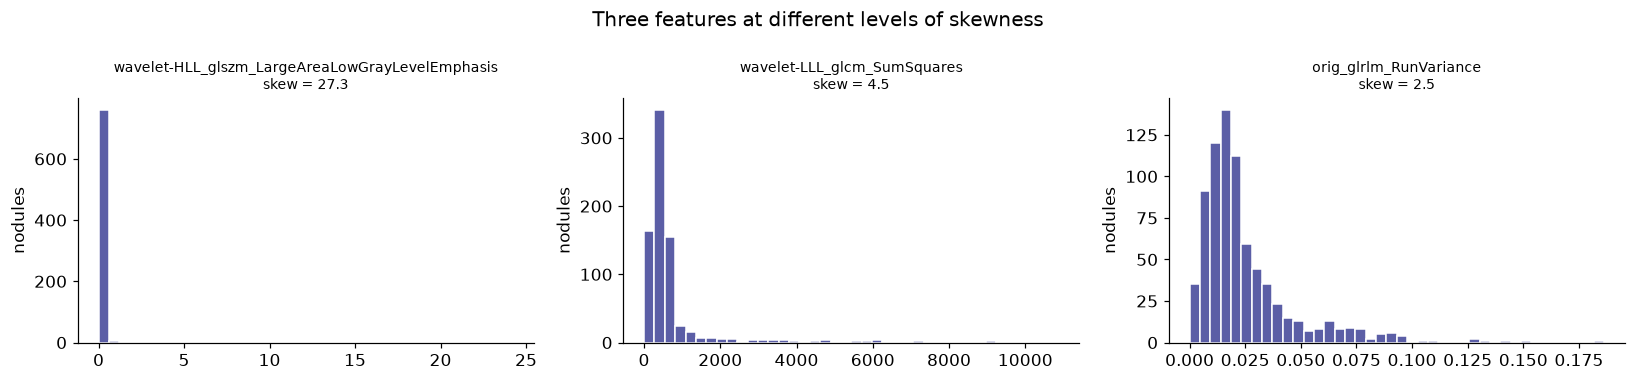

In [3]:
skew = df[features].skew().abs()
print(f'Features with |skewness| > 2: {(skew > 2).sum()} of {len(features)} ({(skew > 2).mean():.0%})')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, f in zip(axes, skew.sort_values(ascending=False).index[[0, len(skew) // 4, len(skew) // 2]]):
    ax.hist(df[f], bins=40, color=U.COLOR_NEUTRAL, edgecolor='white')
    ax.set_title(f'{readable(f)}\nskew = {skew[f]:.1f}', fontsize=9)
    ax.set_ylabel('nodules')
fig.suptitle('Three features at different levels of skewness')
plt.tight_layout(); plt.show()

### 3.2 How many features are relevant?
For each feature, the **Kruskal–Wallis test** asks: *do nodules rated 1, 2, 3, 4 and 5 have
different values of this feature?* It ranks all nodules by the feature and checks whether one
class sits systematically higher or lower. Its statistic **H** grows with the separation; the
**p-value** is the probability of seeing that much separation by chance.

**The multiple-testing trap.** With 1136 tests at the usual 5% level, about 57 features would
look "significant" by pure chance. The **Benjamini–Hochberg FDR correction** adjusts the
p-values (→ q-values) so that, among the features we call relevant, at most 5% are expected to
be false discoveries.

In [4]:
kw = [kruskal(*[X[y == k, j] for k in U.MAL_LABELS]) for j in range(len(features))]
H = np.array([r.statistic for r in kw])
p = np.array([r.pvalue for r in kw])
q = false_discovery_control(p)

relevance = pd.DataFrame({'feature': features, 'source': source, 'H': H, 'p': p, 'q_fdr': q}
                         ).sort_values('H', ascending=False).reset_index(drop=True)

print(f'Relevant at p < 0.05 (no correction): {(p < 0.05).sum()}')
print(f'Relevant at FDR q < {FDR_ALPHA}          : {(q < FDR_ALPHA).sum()}')
print(f'Not relevant                        : {(q >= FDR_ALPHA).sum()}')
relevance.head(10).assign(feature=lambda d: d.feature.map(readable)).round({'H': 1})

Relevant at p < 0.05 (no correction): 1102
Relevant at FDR q < 0.05          : 1101
Not relevant                        : 35


,feature,source,H,p,q_fdr
0,orig_glcm_ClusterShade,original,191.9,2.109971e-40,2.396927e-37
1,orig_firstorder_Skewness,original,181.9,2.932564e-38,1.665697e-35
2,orig_firstorder_RootMeanSquared,original,178.5,1.535722e-37,5.815266e-35
3,LoG σ1mm_glcm_MCC,LoG,156.4,8.582801e-33,2.437516e-30
4,wavelet-LHH_ngtdm_Strength,wavelet,150.1,1.961130e-31,4.455688e-29
5,orig_gldm_LargeDependenceEmphasis,original,146.6,1.086229e-30,1.816095e-28
6,orig_glszm_LargeAreaEmphasis,original,146.2,1.311242e-30,1.816095e-28
7,orig_gldm_DependenceVariance,original,146.2,1.358926e-30,1.816095e-28
8,wavelet-LHH_glcm_MCC,wavelet,145.8,1.584332e-30,1.816095e-28
9,LoG σ1mm_glcm_Imc1,LoG,145.8,1.598675e-30,1.816095e-28


Most features are relevant — malignancy ratings follow size, density and shape, which many measurements pick up.
The real problem is therefore not irrelevance but **redundancy**.

### 3.3 How redundant are they?
Spearman correlation between the 100 most relevant features. The features are **reordered by
hierarchical clustering**, so features that measure the same thing end up next to each other
and appear as bright square blocks on the diagonal.

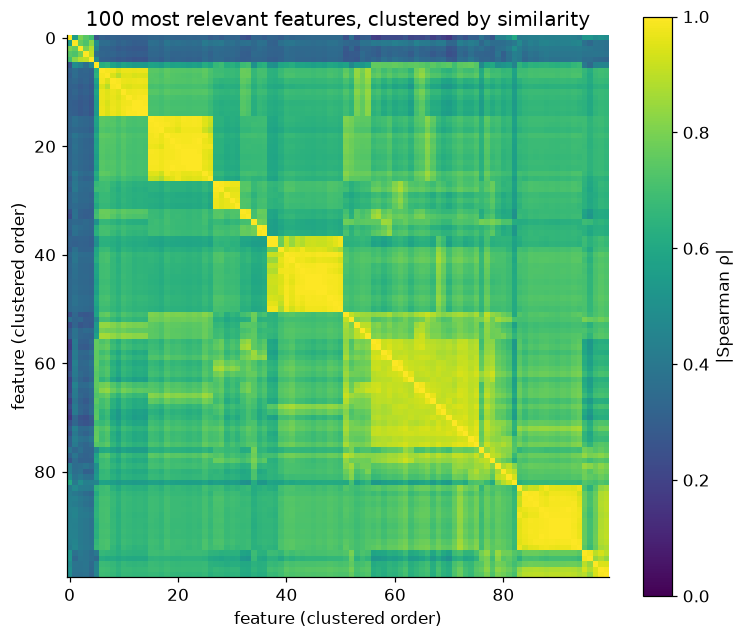

Pairs among the top 100 with |ρ| > 0.85: 11%


In [5]:
top = relevance.feature.head(100).tolist()
rho = df[top].rank().corr().abs().values
order = leaves_list(linkage(squareform(1 - rho, checks=False), method='average'))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(rho[np.ix_(order, order)], cmap='viridis', vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label='|Spearman ρ|')
ax.set(title='100 most relevant features, clustered by similarity',
       xlabel='feature (clustered order)', ylabel='feature (clustered order)')
plt.tight_layout(); plt.show()

iu = np.triu_indices(len(top), 1)
print(f'Pairs among the top 100 with |ρ| > {CORR_THRESHOLD}: {(rho[iu] > CORR_THRESHOLD).mean():.0%}')

## 4. The selection procedure
`RelevanceRedundancySelector` (in `lndb_selection.py`) works in two filters:

1. **Relevance:** keep the features with FDR q < 0.05.
2. **Redundancy:** visit them **from most to least relevant** (highest H first) and keep a
   feature only if its |Spearman ρ| with every feature already kept is below 0.85. Of each group
   of near-duplicates, the most relevant one survives.
3. Stop after *n* features (or keep all survivors).

The funnel below shows how many features survive each step on the whole training set, and
where they come from.

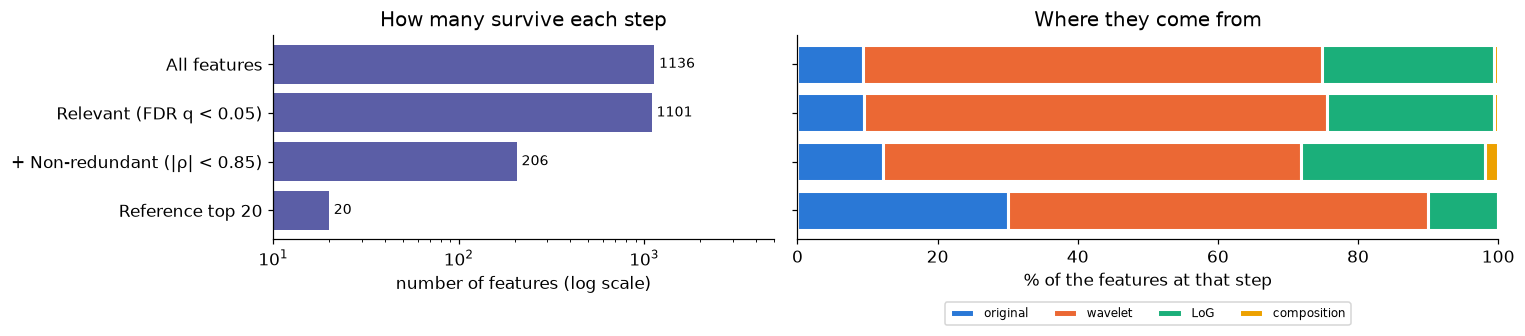

,original,wavelet,LoG,composition,total
All features,107,744,279,6,1136
Relevant (FDR q < 0.05),105,727,263,6,1101
+ Non-redundant (|ρ| < 0.85),25,123,54,4,206
Reference top 20,6,12,2,0,20


In [6]:
relevant_sel = RelevanceRedundancySelector(k=None, corr_threshold=CORR_THRESHOLD, fdr_alpha=FDR_ALPHA).fit(X, y)
reference    = RelevanceRedundancySelector(k=N_REFERENCE, corr_threshold=CORR_THRESHOLD, fdr_alpha=FDR_ALPHA).fit(X, y)

stages = {
    'All features'                     : source,
    f'Relevant (FDR q < {FDR_ALPHA})'  : source[q < FDR_ALPHA],
    f'+ Non-redundant (|ρ| < {CORR_THRESHOLD})': source[relevant_sel.selected_],
    f'Reference top {N_REFERENCE}'     : source[reference.selected_],
}
funnel = pd.DataFrame({name: pd.Series(s).value_counts().reindex(SOURCES, fill_value=0)
                       for name, s in stages.items()}).T

totals = funnel.sum(axis=1)
shares = funnel.div(totals, axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True, gridspec_kw={'width_ratios': [1, 1.4]})
axes[0].barh(funnel.index, totals, color=U.COLOR_NEUTRAL)
axes[0].bar_label(axes[0].containers[0], fmt='%d', padding=3, fontsize=9)
axes[0].set(xscale='log', xlim=(10, 5000), xlabel='number of features (log scale)', title='How many survive each step')
left = np.zeros(len(shares))
for src in SOURCES:          # stacked bars only on a linear (percentage) scale
    axes[1].barh(shares.index, shares[src], left=left, color=U.SOURCE_COLORS[src],
                 edgecolor='white', linewidth=2, label=src)
    left += shares[src].values
axes[1].set(xlim=(0, 100), xlabel='% of the features at that step', title='Where they come from')
axes[1].legend(ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.28))
axes[0].invert_yaxis()
plt.tight_layout(); plt.show()
funnel.assign(total=funnel.sum(axis=1))

**Reading the funnel.** Almost every feature is relevant to malignancy (1101 of 1136): malignancy
ratings follow size, density and shape, which nearly every measurement reflects in some way. The
real problem is therefore **redundancy**: only about one relevant feature in five carries information
not already covered by a more relevant one (206 survive). The reference top 20 comes mostly from the
original image and the wavelet versions — size-, density- and texture-related measurements.

## 5. How many features? — it depends on the model

### 5.1 How we measure
- **Cross-validation:** 4 folds grouped by patient (all nodules of a CT stay in the same fold)
  and stratified by class, **repeated 3 times** with different shuffles → 12 scores per setting.
  With only ~4 nodules of class 5 per fold, a single 4-fold split gives very noisy scores; repeating
  makes comparisons more reliable. (The official LNDb folds are used for the final results in
  Notebook 4.) Every setting is evaluated on **exactly the same 12 splits**, so two settings can
  be compared fold by fold (a *paired* comparison).
- **Selection inside every fold** — the selector is the first step of the pipeline.
- **Before the model**, a quantile transform removes the skew and a scaler puts all features on
  the same scale (both learned on the training part of each fold).
- **Two probe models**, deliberately different:
  - **Logistic regression** — linear, with L2 regularisation and *balanced class weights*
    (mistakes on rare classes cost more).
  - **KNN, 15 neighbours** — classifies a nodule by its 15 most similar training nodules. KNN
    has no class weights, so the minority classes are oversampled with **SMOTE** (synthetic
    examples created between real neighbours, on the training part only).
- **Two metrics:**
  - **Quadratic weighted kappa (QWK)** — one of the competition's metrics: agreement beyond
    chance. Malignancy is ordered (1 < 2 < … < 5), so confusing 1 with 5 is penalised far more
    than confusing neighbouring classes.
  - **Balanced accuracy** — mean recall over the 5 classes. A model that always answers the
    most common class gets 0.20, however imbalanced the data.

In [7]:
def pre():
    """Remove skew (quantile → normal) and standardise."""
    return [('quantile', QuantileTransformer(n_quantiles=200, output_distribution='normal')),
            ('scale', StandardScaler())]

def selector(n):
    """Selection step keeping n features (None = no selection, use every feature)."""
    return [('select', RelevanceRedundancySelector(k=n, corr_threshold=CORR_THRESHOLD,
                                                   fdr_alpha=FDR_ALPHA))] if n else []

PROBES = {
    'Logistic regression': lambda n: Pipeline(selector(n) + pre() + [
        ('model', LogisticRegression(class_weight='balanced', C=0.5, max_iter=4000))]),
    'KNN (15 neighbours) + SMOTE': lambda n: ImbPipeline(selector(n) + pre() + [
        ('smote', SMOTE(random_state=U.RANDOM_STATE)),
        ('model', KNeighborsClassifier(n_neighbors=15, weights='distance'))]),
}

def evaluate(make_pipe, Xm=X) -> dict:
    """Repeated grouped CV. Returns the 12 fold scores of QWK and balanced accuracy."""
    out = {'QWK': [], 'BAcc': []}
    for rep in range(N_REPEATS):
        for tr, va in StratifiedGroupKFold(4, shuffle=True, random_state=rep).split(Xm, y, groups):
            pred = make_pipe().fit(Xm[tr], y[tr]).predict(Xm[va])
            out['QWK'].append(cohen_kappa_score(y[va], pred, weights='quadratic'))
            out['BAcc'].append(balanced_accuracy_score(y[va], pred))
    return {m: np.array(v) for m, v in out.items()}

def summary(scores: dict) -> dict:
    return {f'{m}{s}': f(v) for m, v in scores.items() for s, f in (('', np.mean), ('_sd', np.std))}

def paired(a: np.ndarray, b: np.ndarray, label: str) -> None:
    """Fold-by-fold comparison of two settings evaluated on the same 12 splits."""
    d = a - b
    print(f'{label:<58} {d.mean():+.3f}   (better in {np.sum(d > 0):>2}/{len(d)} folds)')

ALL = len(features)
scores = {(probe, n or ALL): evaluate(lambda: make(n))
          for probe, make in PROBES.items() for n in N_FEATURES_GRID + [None]}
curve = pd.DataFrame([{'probe': probe, 'n_features': n, **summary(s)} for (probe, n), s in scores.items()])
curve.round(3)

,probe,n_features,QWK,QWK_sd,BAcc,BAcc_sd
0,Logistic regression,5,0.445,0.045,0.442,0.042
1,Logistic regression,10,0.453,0.029,0.433,0.049
2,Logistic regression,20,0.447,0.040,0.436,0.048
3,Logistic regression,50,0.450,0.056,0.413,0.039
4,Logistic regression,100,0.441,0.061,0.399,0.052
5,Logistic regression,1136,0.385,0.084,0.370,0.045
6,KNN (15 neighbours) + SMOTE,5,0.403,0.087,0.379,0.055
7,KNN (15 neighbours) + SMOTE,10,0.411,0.050,0.374,0.045
8,KNN (15 neighbours) + SMOTE,20,0.420,0.050,0.402,0.047
9,KNN (15 neighbours) + SMOTE,50,0.372,0.071,0.397,0.051


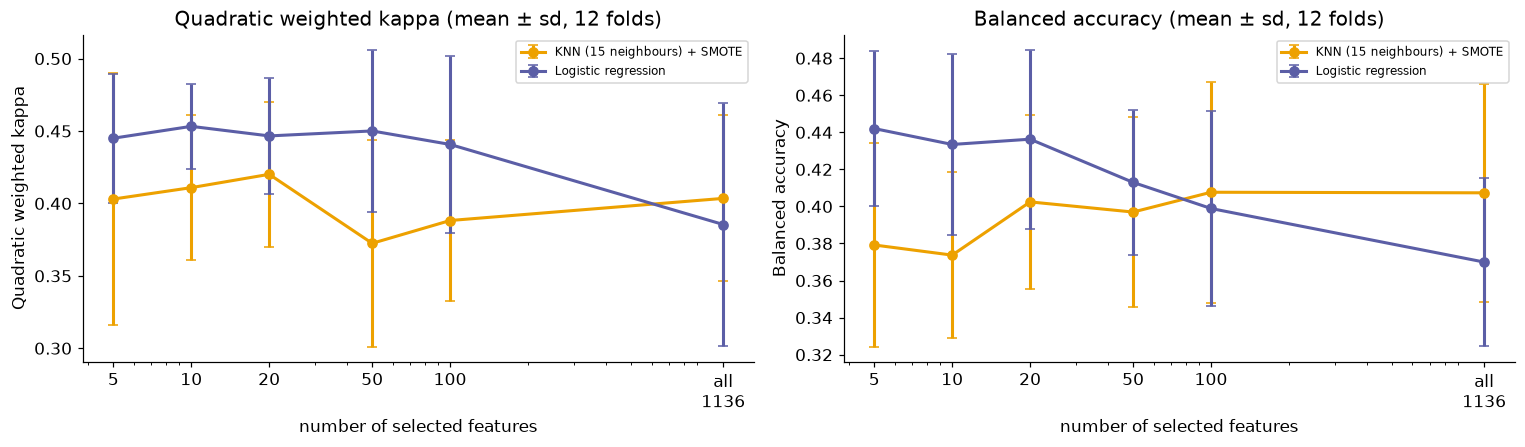

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
probe_colors = {'Logistic regression': U.COLOR_NEUTRAL, 'KNN (15 neighbours) + SMOTE': U.SOURCE_COLORS['composition']}
for ax, m, label in [(axes[0], 'QWK', 'Quadratic weighted kappa'), (axes[1], 'BAcc', 'Balanced accuracy')]:
    for probe_name, g in curve.groupby('probe'):
        ax.errorbar(g.n_features, g[m], yerr=g[m + '_sd'], marker='o', capsize=3, lw=2,
                    label=probe_name, color=probe_colors[probe_name])
    ticks = N_FEATURES_GRID + [ALL]
    ax.set(xscale='log', xticks=ticks, xticklabels=[str(t) for t in N_FEATURES_GRID] + [f'all\n{ALL}'],
           xlabel='number of selected features', ylabel=label, title=f'{label} (mean ± sd, 12 folds)')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.2 Are the differences real? — paired comparisons
The error bars are wide, but they overstate the uncertainty of a *comparison*: a hard fold is
hard for every setting. Comparing two settings **on the same fold** removes that shared noise.
For each comparison we print the mean difference and in how many of the 12 folds the first
setting won. (The 12 folds share training nodules, so they are not independent and a formal
p-value would be over-confident; the win count is an honest, simple summary. Roughly: 10+ out
of 12 is a consistent difference, around 6 out of 12 is noise.)

In [9]:
def best_selected(probe, metric='QWK'):
    """Number of features (among the selected settings) with the best mean metric."""
    return max(N_FEATURES_GRID, key=lambda n: scores[(probe, n)][metric].mean())

lr, knn = 'Logistic regression', 'KNN (15 neighbours) + SMOTE'
n_knn, n_lr = best_selected(knn), best_selected(lr, 'BAcc')

print('Difference (first − second)                               mean     consistency')
paired(scores[(knn, n_knn)]['QWK'], scores[(knn, ALL)]['QWK'], f'KNN QWK: {n_knn} selected − all {ALL}')
paired(scores[(lr, ALL)]['QWK'], scores[(lr, n_lr)]['QWK'], f'LogReg QWK: all {ALL} − {n_lr} selected')
paired(scores[(lr, n_lr)]['BAcc'], scores[(lr, ALL)]['BAcc'], f'LogReg balanced acc.: {n_lr} selected − all {ALL}')

Difference (first − second)                               mean     consistency
KNN QWK: 20 selected − all 1136                            +0.017   (better in  8/12 folds)
LogReg QWK: all 1136 − 5 selected                          -0.060   (better in  3/12 folds)
LogReg balanced acc.: 5 selected − all 1136                +0.072   (better in 11/12 folds)


### 5.3 What this means
1. **For malignancy, fewer features are better for both probes.** The logistic regression reaches its
   best QWK with 10–50 selected features and loses about 0.06 of QWK with all 1136 (worse in 9 of 12
   folds); its balanced accuracy is better with 5 features in 11 of 12 folds. KNN is best with ~20.
   With ~765 nodules and 5 ordered classes, a thousand weakly informative features add more noise
   than signal — the **curse of dimensionality** for KNN, over-fitting for the linear model.
2. **This differs from texture** (appendix), where the regularised model preferred all features: the
   texture signal is spread thinly over many filtered images, whereas malignancy is driven by a few
   strong properties (size, density, border).

**Decision.** There is still no single best number for every model, so it is **not** fixed here.
Notebook 4 tunes the number of selected features **per model** (KNN, SVM, MLP), choosing among the
candidates 5, 10, 20, 50, 100 and "all".

## 6. Creative analysis — were the ~1000 features worth it?
The ~1000 features come from adding wavelet and LoG filtered images to the original image. Is
that extra information useful, or would the 107 original features — or even our 6 composition
features — be enough? We repeat the logistic regression probe on different feature pools,
with every feature of the pool and with the top 20 selected from it.

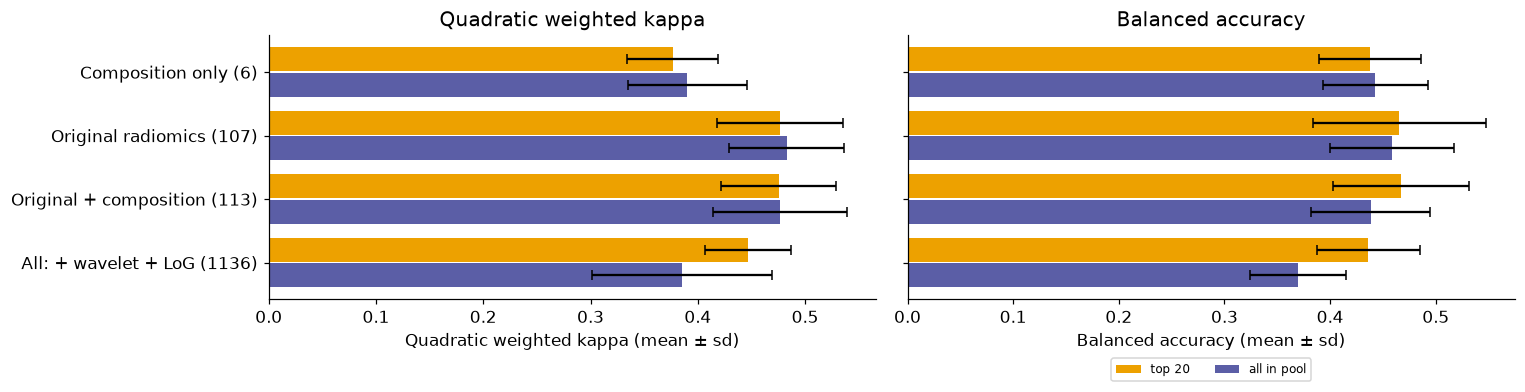

QWK               BAcc       
setting                      all in pool top 20 all in pool top 20
feature pool                                                      
Composition only (6)               0.390  0.376       0.443  0.438
Original radiomics (107)           0.483  0.477       0.458  0.466
Original + composition (113)       0.476  0.475       0.439  0.467
All: + wavelet + LoG (1136)        0.385  0.447       0.370  0.436

In [10]:
pools = {
    'Composition only (6)'          : [f for f in features if image_type(f) == 'composition'],
    'Original radiomics (107)'      : [f for f in features if image_type(f) == 'original'],
    'Original + composition (113)'  : [f for f in features if image_type(f) in ('original', 'composition')],
    f'All: + wavelet + LoG ({ALL})' : features,
}
make_lr = PROBES[lr]
pool_scores = {}
for name, cols in pools.items():
    Xp = df[cols].values
    pool_scores[(name, 'all in pool')] = evaluate(lambda: make_lr(None), Xp)
    pool_scores[(name, f'top {N_REFERENCE}')] = evaluate(lambda: make_lr(min(N_REFERENCE, len(cols))), Xp)

pool_res = pd.DataFrame([{'feature pool': name, 'setting': setting, **summary(s)}
                         for (name, setting), s in pool_scores.items()])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
names = list(pools)
yy = np.arange(len(names))
for ax, m, label in [(axes[0], 'QWK', 'Quadratic weighted kappa'), (axes[1], 'BAcc', 'Balanced accuracy')]:
    for off, setting, color in [(-0.2, f'top {N_REFERENCE}', U.SOURCE_COLORS['composition']),
                                (0.2, 'all in pool', U.COLOR_NEUTRAL)]:
        r = pool_res[pool_res.setting == setting].set_index('feature pool').loc[names]
        ax.barh(yy + off, r[m], height=0.38, xerr=r[m + '_sd'], capsize=3, color=color, label=setting)
    ax.set(yticks=yy, yticklabels=names, xlabel=f'{label} (mean ± sd)', title=label)
axes[0].invert_yaxis()
axes[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.show()
pool_res.pivot(index='feature pool', columns='setting', values=['QWK', 'BAcc']).loc[names].round(3)

In [11]:
A, O, C = names[3], names[1], names[0]
print('Difference (first − second)                               mean     consistency')
paired(pool_scores[(A, 'all in pool')]['QWK'], pool_scores[(O, 'all in pool')]['QWK'],
       'QWK, all features in pool: All 1136 − Original 107')
paired(pool_scores[(A, f'top {N_REFERENCE}')]['QWK'], pool_scores[(O, f'top {N_REFERENCE}')]['QWK'],
       f'QWK, top {N_REFERENCE} selected: All 1136 − Original 107')
paired(pool_scores[(C, 'all in pool')]['QWK'], pool_scores[(O, 'all in pool')]['QWK'],
       'QWK: Composition 6 − Original 107')
paired(pool_scores[(C, 'all in pool')]['BAcc'], pool_scores[(O, 'all in pool')]['BAcc'],
       'Balanced acc.: Composition 6 − Original 107')

Difference (first − second)                               mean     consistency
QWK, all features in pool: All 1136 − Original 107         -0.097   (better in  2/12 folds)
QWK, top 20 selected: All 1136 − Original 107              -0.030   (better in  5/12 folds)
QWK: Composition 6 − Original 107                          -0.093   (better in  0/12 folds)
Balanced acc.: Composition 6 − Original 107                -0.015   (better in  5/12 folds)


**What the comparison shows.**
1. **For malignancy, the 107 original-image features are enough for a linear model** — adding the
   ~1000 wavelet and LoG features *lowers* the QWK of the logistic regression with every feature in
   the pool (worse in 10 of 12 folds), and even the top 20 picked from all 1136 is no better than the
   top 20 from the original image. The filtered images mostly repeat the original information.
2. **The 6 composition features alone are clearly weaker** (QWK 0.39 vs 0.48) — they describe
   density, but not size and shape well enough.
3. **Why keep the 1136 then?** These are linear probes. The models of Notebook 4 tune the number of
   features themselves, and non-linear models (SVM, MLP, a committee) can exploit combinations a
   linear probe cannot. The extraction also serves LIDC-IDRI (Notebook 5) and the 2D vs 3D check.
   Keeping the large pool and **letting cross-validation choose** is the safe option; this section
   shows that the choice matters.

## 7. Stability — would we pick the same features with different patients?
A trustworthy selection should not change completely when the training data change a little.
We re-run the reference selection (top 20) on the training part of each of the 12 folds and
count how often each feature is picked.

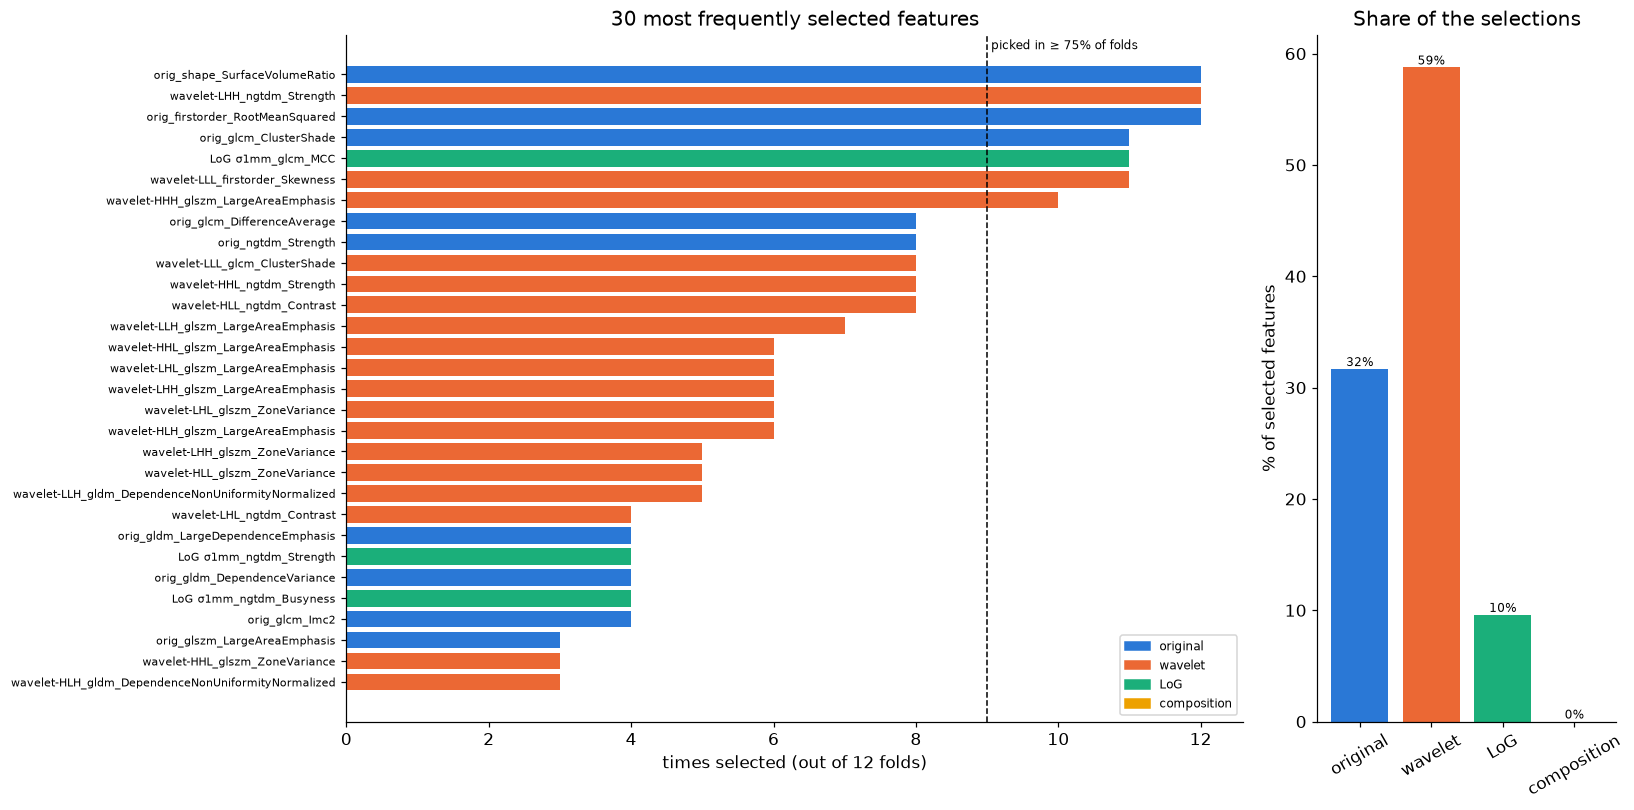

Mean Jaccard similarity between fold selections: 0.39 (1 = identical sets)
Features picked in ≥ 75% of folds: 7
Composition features: 0.5% of the candidates, 0% of the selections; stable ones: []


In [12]:
picked = []
for rep in range(N_REPEATS):
    for tr, _ in StratifiedGroupKFold(4, shuffle=True, random_state=rep).split(X, y, groups):
        sel = RelevanceRedundancySelector(k=N_REFERENCE, corr_threshold=CORR_THRESHOLD, fdr_alpha=FDR_ALPHA).fit(X[tr], y[tr])
        picked.append(set(sel.selected_names(features)))
n_runs = len(picked)

freq = pd.Series([f for s in picked for f in s]).value_counts()
jaccard = [len(a & b) / len(a | b) for i, a in enumerate(picked) for b in picked[i + 1:]]
share = (pd.Series([image_type(f) for s in picked for f in s]).value_counts().reindex(SOURCES, fill_value=0)
         / (n_runs * N_REFERENCE))
stable = freq[freq >= 0.75 * n_runs]

shown = freq.head(30)
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), gridspec_kw={'width_ratios': [3, 1]})
axes[0].barh([readable(f) for f in shown.index], shown.values,
             color=[U.SOURCE_COLORS[image_type(f)] for f in shown.index])
axes[0].axvline(0.75 * n_runs, color='black', ls='--', lw=1)
axes[0].text(0.75 * n_runs, -1.2, ' picked in ≥ 75% of folds', fontsize=8)
axes[0].set(xlabel=f'times selected (out of {n_runs} folds)', title='30 most frequently selected features')
axes[0].invert_yaxis(); axes[0].tick_params(axis='y', labelsize=7)
axes[1].bar(share.index, share.values * 100, color=[U.SOURCE_COLORS[s] for s in share.index])
axes[1].bar_label(axes[1].containers[0], fmt='%.0f%%', fontsize=8)
axes[1].set(title='Share of the selections', ylabel='% of selected features'); axes[1].tick_params(axis='x', rotation=30)
handles = [plt.Rectangle((0, 0), 1, 1, color=U.SOURCE_COLORS[s]) for s in SOURCES]
axes[0].legend(handles, SOURCES, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

print(f'Mean Jaccard similarity between fold selections: {np.mean(jaccard):.2f} (1 = identical sets)')
print(f'Features picked in ≥ 75% of folds: {len(stable)}')
print(f'Composition features: {(source == "composition").mean():.1%} of the candidates, '
      f'{share["composition"]:.0%} of the selections; stable ones: '
      f'{[readable(f) for f in stable.index if image_type(f) == "composition"]}')

**Reading the stability plot.** Feature-level stability is moderate (Jaccard ≈ 0.4): many features
are nearly interchangeable (the same zone-size measure on several wavelet images), so a small change
in the data makes the selector pick one or the other. What is stable is the **kind of information**
chosen and a core of 7 features picked in at least 75% of the folds — among them the root mean squared
intensity, the surface-to-volume ratio (shape), and a GLCM measure of asymmetry. Those are the most
trustworthy to interpret. The composition features, so important for texture, are not selected for
malignancy: they are relevant but redundant with stronger intensity features.

## 8. Creative analysis — which distinctions are hard?
Kruskal–Wallis tells us a feature separates the 5 classes *somewhere*, but not **where**. For each
reference feature we compute the **AUC** of the neighbouring distinctions (1 vs 2, 2 vs 3, 3 vs 4,
4 vs 5) and of the clinically decisive one, **benign (1–2) vs suspicious (4–5)**: the probability
that a random nodule of one group has a higher (or lower) value than a random nodule of the other.
0.5 = no separation, 1.0 = perfect separation.

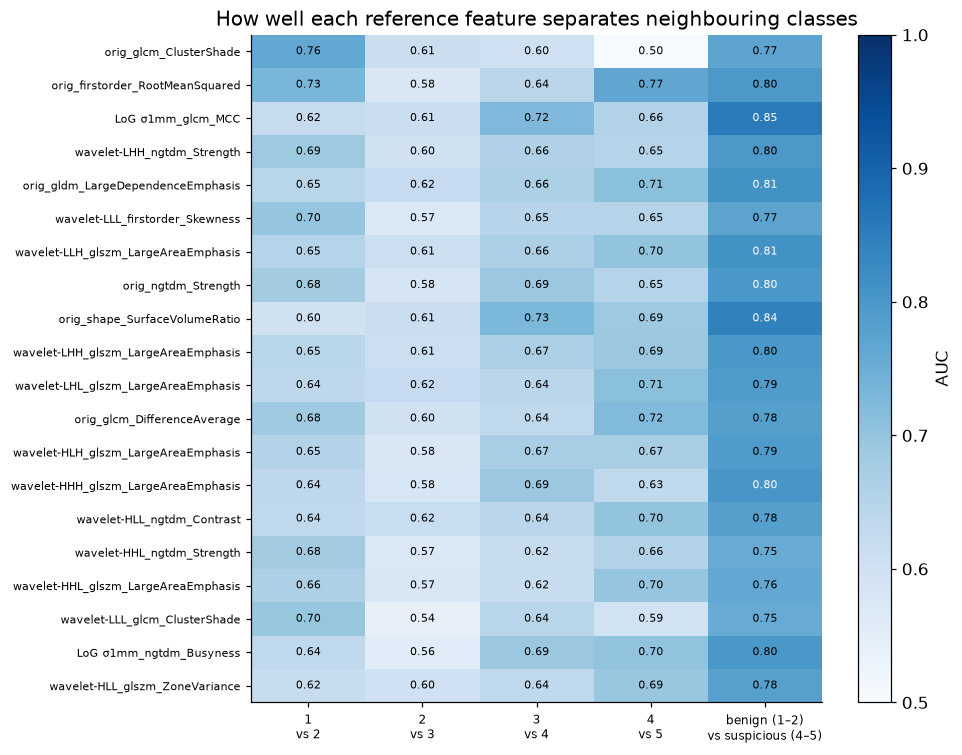

,1 vs 2,2 vs 3,3 vs 4,4 vs 5,benign (1–2) vs suspicious (4–5)
median,0.65,0.60,0.65,0.69,0.80
max,0.76,0.62,0.73,0.77,0.85


In [13]:
groups_def = {'1 vs 2': ([1], [2]), '2 vs 3': ([2], [3]), '3 vs 4': ([3], [4]), '4 vs 5': ([4], [5]),
              'benign (1–2) vs suspicious (4–5)': ([1, 2], [4, 5])}
ref_features = reference.selected_names(features)

auc = pd.DataFrame(index=[readable(f) for f in ref_features], columns=list(groups_def), dtype=float)
for f in ref_features:
    for name, (a_cls, b_cls) in groups_def.items():
        mask = np.isin(y, a_cls + b_cls)
        a = roc_auc_score(np.isin(y[mask], b_cls), df.loc[mask, f])
        auc.loc[readable(f), name] = max(a, 1 - a)        # direction does not matter here

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(auc.values, cmap='Blues', vmin=0.5, vmax=1, aspect='auto')
ax.set_xticks(range(auc.shape[1]), [c.replace(' vs ', '\nvs ') for c in auc.columns], fontsize=8)
ax.set_yticks(range(len(auc)), auc.index, fontsize=7)
for r in range(len(auc)):
    for c in range(auc.shape[1]):
        v = auc.values[r, c]
        ax.text(c, r, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if v > 0.8 else 'black')
plt.colorbar(im, ax=ax, label='AUC')
ax.set_title('How well each reference feature separates neighbouring classes')
plt.tight_layout(); plt.show()

auc.agg(['median', 'max']).round(2)

**The key finding for the models.** No single feature separates neighbouring classes well
(median AUC 0.60–0.69; best ≈ 0.62 for **2 vs 3**, the hardest step). The clinically decisive
distinction — **benign (1–2) vs suspicious (4–5)** — is much easier (median AUC 0.80, best 0.85).
So the models should get the *broad* level right, while exact neighbouring classes will be confused
— exactly where radiologists disagree (Notebook 1: 83% of reader pairs within ±1, only 41% exact).
Ordered metrics (QWK, MAE) reward getting the broad level right, which is why our models predict the
ordered score (Notebook 4).

## 9. Reference selection and settings for Notebook 4
The reference list (top 20, learned on all training nodules) is used to **interpret** what
distinguishes the classes. For **performance**, Notebook 4 re-runs the selection inside each fold
and tunes the number of features per model.

In [14]:
pd.DataFrame({
    'feature': [readable(f) for f in ref_features],
    'source' : [image_type(f) for f in ref_features],
    'H'      : reference.h_[reference.selected_].round(1),
    f'stable (of {n_runs} folds)': [int(freq.get(f, 0)) for f in ref_features],
}, index=range(1, len(ref_features) + 1))

,feature,source,H,stable (of 12 folds)
1,orig_glcm_ClusterShade,original,191.9,11
2,orig_firstorder_RootMeanSquared,original,178.5,12
3,LoG σ1mm_glcm_MCC,LoG,156.4,11
4,wavelet-LHH_ngtdm_Strength,wavelet,150.1,12
5,orig_gldm_LargeDependenceEmphasis,original,146.6,4
6,wavelet-LLL_firstorder_Skewness,wavelet,143.4,11
7,wavelet-LLH_glszm_LargeAreaEmphasis,wavelet,142.4,7
8,orig_ngtdm_Strength,original,141.2,8
9,orig_shape_SurfaceVolumeRatio,original,140.2,12
10,wavelet-LHH_glszm_LargeAreaEmphasis,wavelet,139.5,6


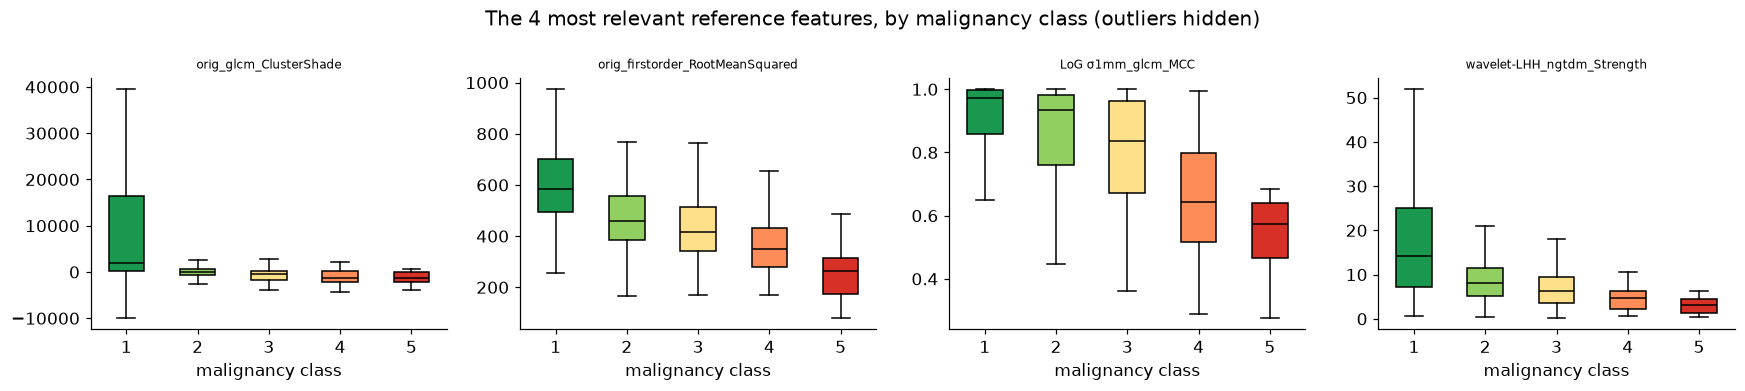

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, f in zip(axes, ref_features[:4]):
    box = ax.boxplot([df.loc[y == k, f] for k in U.MAL_LABELS], tick_labels=[str(k) for k in U.MAL_LABELS],
                     patch_artist=True, medianprops=dict(color='black'), showfliers=False)
    for patch, col in zip(box['boxes'], U.MALIGNANCY_COLORS):
        patch.set_facecolor(col)
    ax.set_xlabel('malignancy class')
    ax.set_title(readable(f), fontsize=8)
fig.suptitle('The 4 most relevant reference features, by malignancy class (outliers hidden)')
plt.tight_layout(); plt.show()

In [16]:
selection = {
    'corr_threshold'        : CORR_THRESHOLD,
    'fdr_alpha'             : FDR_ALPHA,
    'n_features_candidates' : N_FEATURES_GRID + ['all'],
    'n_input_features'      : ALL,
    'n_relevant_fdr'        : int(reference.n_relevant_),
    'n_non_redundant'       : int(len(relevant_sel.selected_)),
    'reference_n'           : N_REFERENCE,
    'reference_features'    : ref_features,
    'stable_features'       : list(stable.index),
}
with open(U.OUTPUT_DIR / 'selected_features.json', 'w') as fh:
    json.dump(selection, fh, indent=2)
print('Saved selection settings → outputs/selected_features.json')

Saved selection settings → outputs/selected_features.json


---
## Summary

| Step | Decision | Reason |
|---|---|---|
| Rank-based statistics | Kruskal–Wallis, Spearman | ~60% of the features are heavily skewed |
| Relevance | Kruskal–Wallis (5 classes) + Benjamini–Hochberg FDR (5%) | 1136 simultaneous tests |
| Redundancy | Greedy: keep the most relevant of each correlated group (\|ρ\| < 0.85) | 1101 relevant features, only ~200 non-redundant |
| No leakage | Selection re-fitted inside every fold (scikit-learn transformer) | Validation nodules must not influence feature choice |
| Evaluation | Repeated (3×) grouped, stratified 4-fold CV; paired comparisons | One split is too noisy with ~4 nodules rated 5 per fold |
| Number of features | Not fixed: tuned per model in Notebook 4 | For malignancy both probes prefer a selected set (10–50) |
| Feature pools | Original-image features carry most of the linear signal | Filtered images mostly repeat it for this target |
| Hard distinctions | Neighbouring classes (2 vs 3 hardest); benign vs suspicious is easier | Same pattern as the radiologists' disagreements |

**Next → Notebook 4:** train and compare KNN, SVM and MLP — and our score committee — tuning the
number of selected features for each model.